Stroke Prediction Dataset — Exploratory Data Analysis (EDA)

Introduction

The purpose of this project is to perform Exploratory Data Analysis (EDA) on the Stroke Prediction Dataset from Kaggle.

The analysis explores the dataset's structure, data quality, statistical summaries, and distributions of relevant variables. Visualizations are used to investigate patterns and associations between stroke status and features such as age, gender, BMI, glucose level, hypertension, and heart disease.

Objectives

- Understand the dataset's structure and features.
- Identify missing values and duplicate records.
- Explore numerical and categorical variables.
- Visualize the distribution of stroke cases.
- Summarize key observations and limitations.

Tools and Libraries

- Python
- Pandas
- Matplotlib
- Seaborn
- Kaggle Notebooks

## 1. Locate the Dataset

This step identifies the dataset files available in the Kaggle input directory and displays their file paths.

In [1]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/fedesoriano/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv


## 2. Import Libraries and Load the Dataset

Pandas is used to load and manipulate the dataset. Matplotlib and Seaborn are used to create visualizations. The first five rows are displayed to inspect the dataset.

In [2]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/fedesoriano/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv')

df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 3. Dataset Overview

This step examines the number of rows and columns and lists all variables in the dataset.

In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (5110, 12)

Column names:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


## 4. Dataset Information and Missing Values

This step examines the data types of the columns and identifies missing values that may require data cleaning.

In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB

Missing Values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease      

## 5. Duplicate Record Analysis

This step checks whether any complete rows are repeated in the dataset. Duplicate records can affect data analysis if they are not appropriately handled.

In [5]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


## 6. Statistical Summary

Descriptive statistics summarize numerical variables using measures such as mean, standard deviation, minimum, maximum, and quartiles.

In [6]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


## 7. Distribution of Stroke Cases

This step examines the number and percentage of participants with and without a recorded stroke. It helps determine whether the target variable is balanced.

In [7]:
print("Stroke case counts:")
print(df["stroke"].value_counts())

print("\nStroke case percentages:")
print(df["stroke"].value_counts(normalize=True).mul(100).round(2))

Stroke case counts:
stroke
0    4861
1     249
Name: count, dtype: int64

Stroke case percentages:
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


## 8. Visualization of Stroke Cases

A count plot compares the number of participants in each stroke category. This visualization helps illustrate the distribution of the target variable.

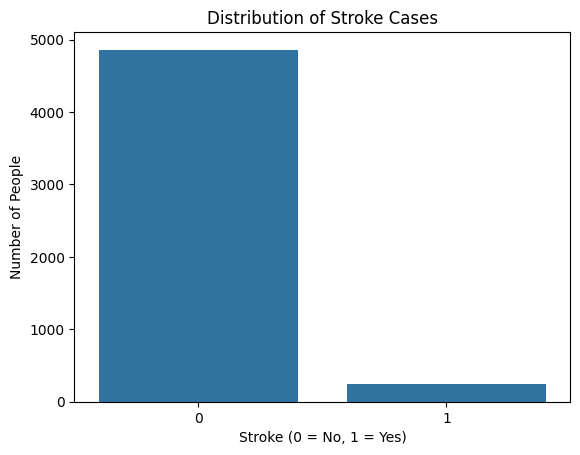

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="stroke")
plt.title("Distribution of Stroke Cases")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Number of People")
plt.show()

## 9. Age Distribution

A histogram with a density curve is used to examine the distribution of participant ages and identify common age ranges.

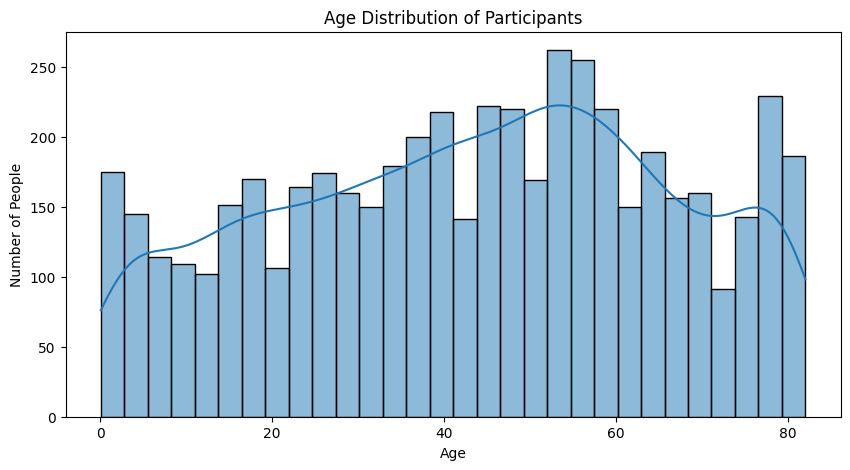

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="age", bins=30, kde=True)

plt.title("Age Distribution of Participants")
plt.xlabel("Age")
plt.ylabel("Number of People")
plt.show()

## 10. Age Distribution by Stroke Status

A box plot compares age distributions between participants with and without a recorded stroke. It helps compare the median, spread, and potential outliers in each group.

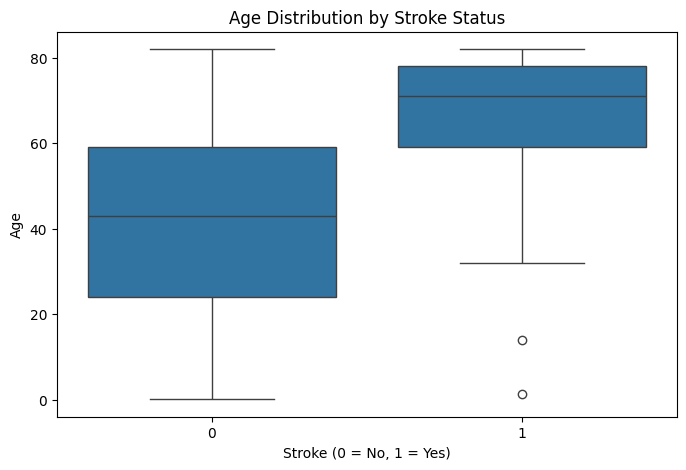

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="stroke", y="age")

plt.title("Age Distribution by Stroke Status")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Age")
plt.show()

## 11. Stroke Cases by Gender

This count plot compares the recorded stroke categories across gender groups. The results represent counts rather than stroke rates within each group.

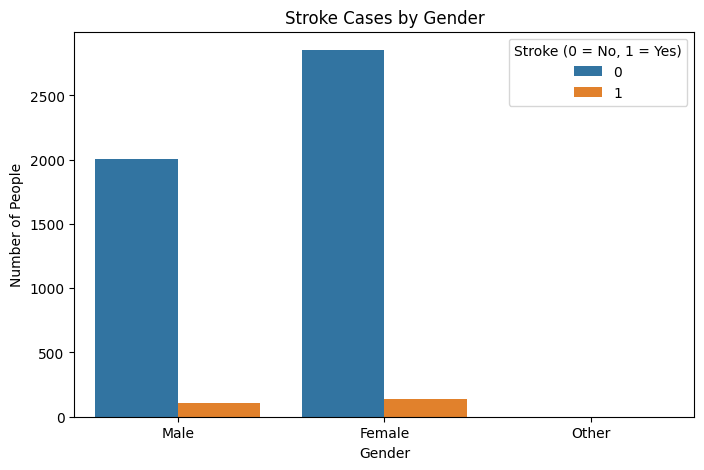

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="gender", hue="stroke")

plt.title("Stroke Cases by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of People")
plt.legend(title="Stroke (0 = No, 1 = Yes)")
plt.show()

## 12. Stroke Cases by Smoking Status

This visualization compares recorded stroke counts across smoking-status categories. Differences in group sizes should be considered when interpreting the chart.

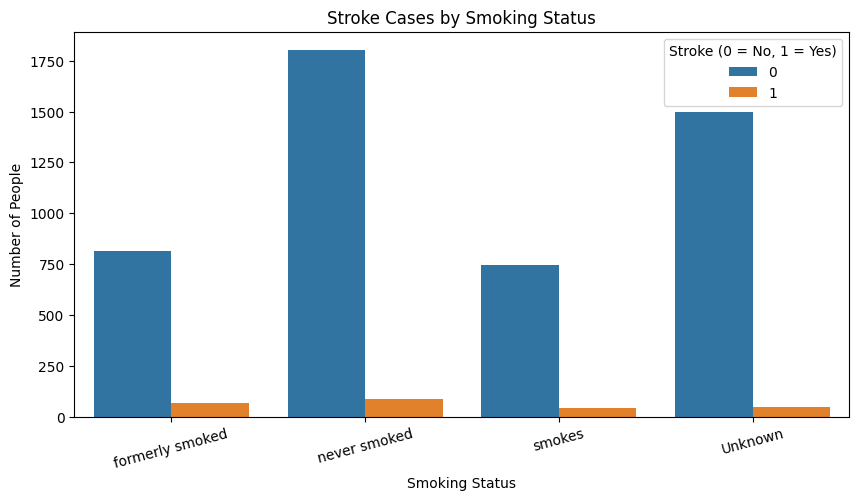

In [12]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="smoking_status", hue="stroke")

plt.title("Stroke Cases by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Number of People")
plt.xticks(rotation=15)
plt.legend(title="Stroke (0 = No, 1 = Yes)")
plt.show()

## 13. Stroke Cases by Hypertension and Heart Disease

These visualizations compare recorded stroke counts among participants with and without hypertension and heart disease.

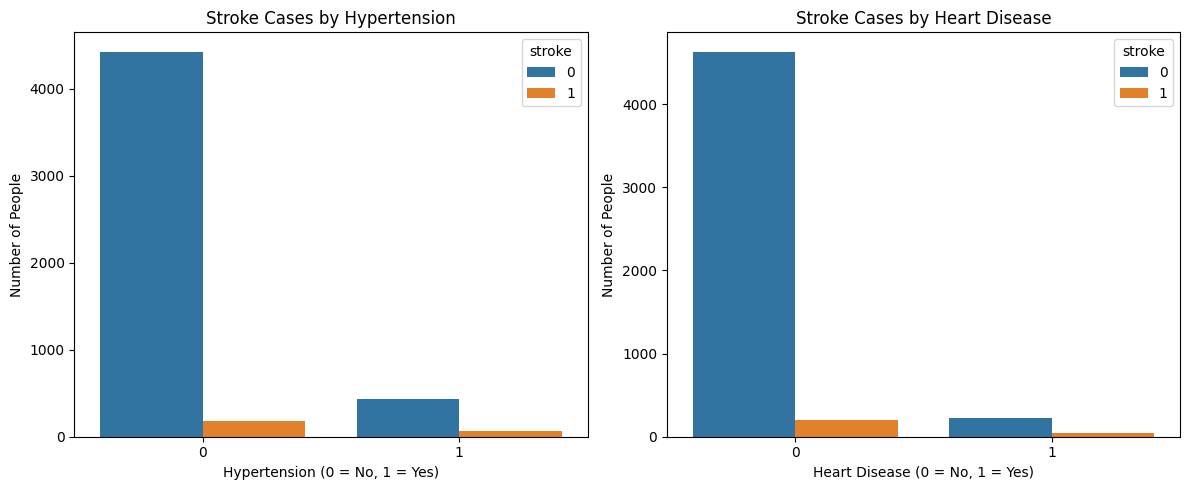

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x="hypertension", hue="stroke", ax=axes[0])
axes[0].set_title("Stroke Cases by Hypertension")
axes[0].set_xlabel("Hypertension (0 = No, 1 = Yes)")
axes[0].set_ylabel("Number of People")

sns.countplot(data=df, x="heart_disease", hue="stroke", ax=axes[1])
axes[1].set_title("Stroke Cases by Heart Disease")
axes[1].set_xlabel("Heart Disease (0 = No, 1 = Yes)")
axes[1].set_ylabel("Number of People")

plt.tight_layout()
plt.show()

## 14. Stroke Cases by Work Type

This visualization explores how recorded stroke cases are distributed across different employment categories.

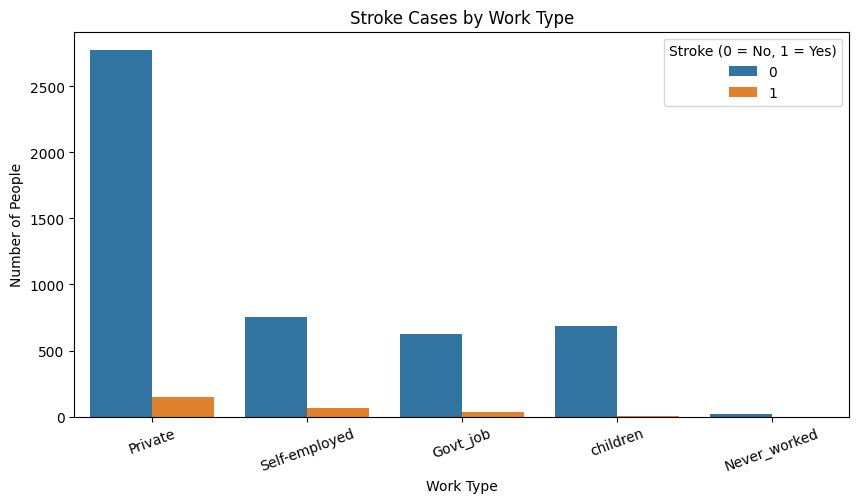

In [14]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="work_type", hue="stroke")

plt.title("Stroke Cases by Work Type")
plt.xlabel("Work Type")
plt.ylabel("Number of People")
plt.xticks(rotation=20)
plt.legend(title="Stroke (0 = No, 1 = Yes)")
plt.show()

## 15. Missing Value Analysis

This step counts missing values in each column and calculates the total number of missing cells in the dataset.

In [15]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
bmi    201
dtype: int64

Total missing values: 201


## 16. Visualization of Missing Values

A heatmap displays the locations of missing values across the dataset and helps identify columns that need attention during data cleaning.

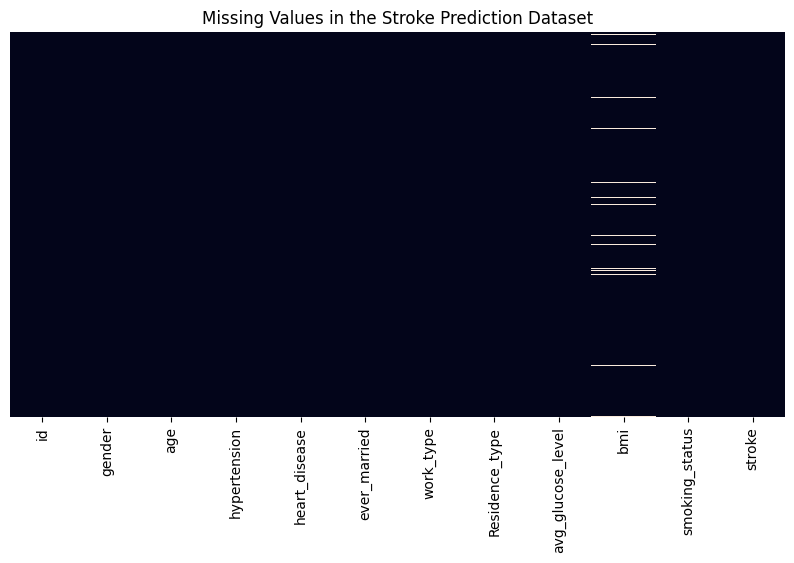

In [16]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False)

plt.title("Missing Values in the Stroke Prediction Dataset")
plt.show()

## 17. BMI Distribution

This histogram examines the distribution of Body Mass Index (BMI) values and helps identify the overall shape of the distribution.

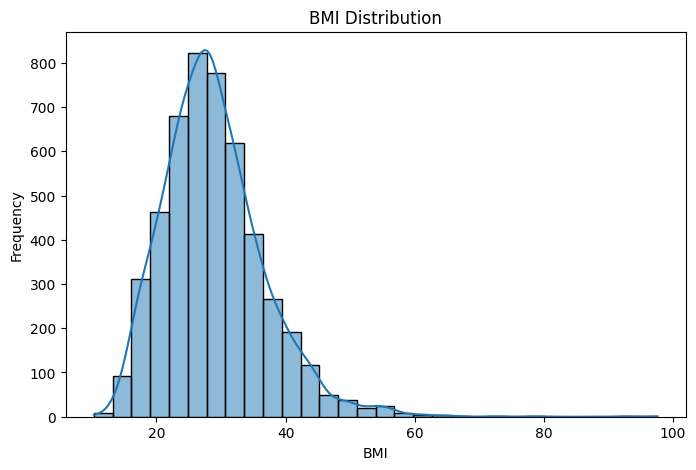

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="bmi", bins=30, kde=True)

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.show()

## 18. Data Quality and Dataset Structure

This step reviews missing values, data types, and dataset dimensions before further analysis. It helps confirm the dataset's structure and data-quality issues.

In [18]:
print("Missing values by column:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

print("\nDataset shape:")
print(df.shape)

Missing values by column:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Data types:
id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object

Dataset shape:
(5110, 12)


## 19. Numerical Features by Stroke Status

This step compares the average age, average glucose level, and BMI between participants with and without a recorded stroke. These differences may indicate associations but do not establish causation.

In [19]:
numeric_cols = [
    "age",
    "avg_glucose_level",
    "bmi"
]

df.groupby("stroke")[numeric_cols].mean().round(2)

,age,avg_glucose_level,bmi
stroke,,,
0,41.97,104.80,28.82
1,67.73,132.54,30.47


## 20. Handling Missing BMI Values

Missing BMI values are replaced with the median BMI. The missing-value count is checked before and after imputation to verify the change. This cleaning step modifies the DataFrame used in subsequent analysis.

In [20]:
print("Missing BMI values before cleaning:", df["bmi"].isnull().sum())

df["bmi"] = df["bmi"].fillna(df["bmi"].median())

print("Missing BMI values after cleaning:", df["bmi"].isnull().sum())

Missing BMI values before cleaning: 201
Missing BMI values after cleaning: 0


## 21. Correlation Heatmap

A correlation heatmap summarizes pairwise correlations among numerical columns. Correlations can help identify relationships worth investigating, but they do not establish causation. Encoded categorical variables should be interpreted carefully.

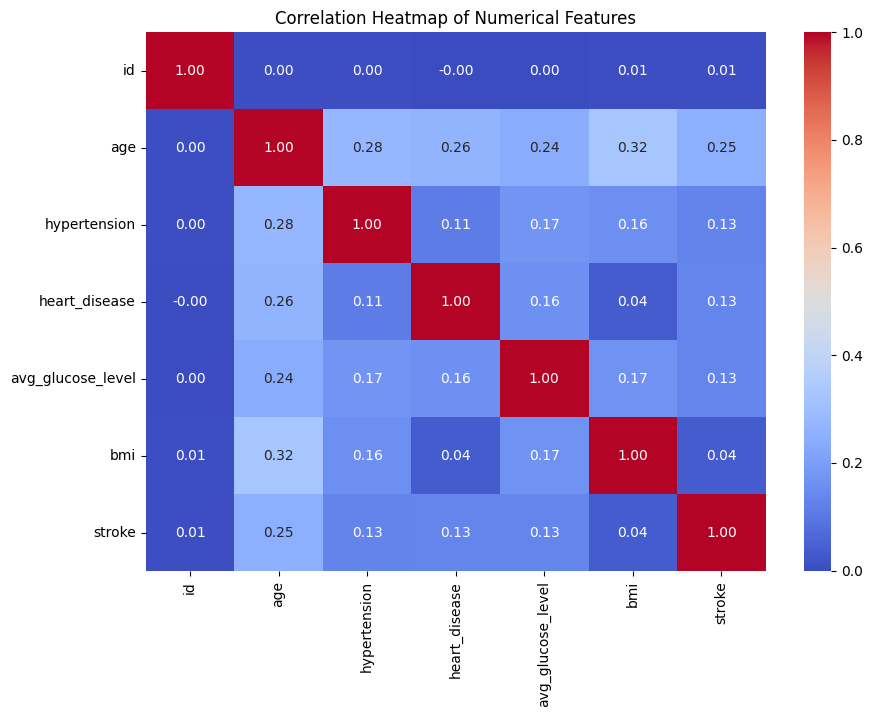

In [21]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Numerical Features")
plt.show()